# Data-Driven Clothing for Interactive Applications

### ML Mini Project

**Reference Paper:** Data-Driven Clothing for Interactive Applications  
**Authors:** Kangrui Xue and Jane Wu  
**Implementation:** Synthetic simulation-inspired dataset + PCA + Machine Learning

---

## Project Overview

This project implements a simplified version of the data-driven clothing
prediction approach described in the reference paper.

The goal is to learn the relationship between human body pose parameters
and clothing deformation using machine learning.

The project uses:
- 14 joint rotation quaternions
- 56 pose input features
- 2,170 clothing vertices
- 6,510 clothing deformation values
- PCA for dimensionality reduction
- Linear Regression as a baseline
- A fully connected neural network for clothing deformation prediction

## Important Dataset Note

The original paper describes a dataset generated using offline procedural
cloth simulation. Since the original numerical dataset was not publicly
provided for this project, a reproducible synthetic, simulation-inspired
dataset was generated following the input/output dimensional structure
described in the paper.

Therefore, the results in this notebook are the results of this
implementation and should not be interpreted as a reproduction of the
paper's reported numerical results.

In [1]:
import os

os.makedirs("Data_Driven_Clothing_ML", exist_ok=True)

print("Folder created!")

Folder created!


In [2]:

import os

os.makedirs("/content/Data_Driven_Clothing_ML", exist_ok=True)

print("Folder created successfully!")
print("Current location:", os.getcwd())
print("Folders available:", os.listdir("/content"))

Folder created successfully!
Current location: /content
Folders available: ['.config', 'Data_Driven_Clothing_ML', 'sample_data']


In [3]:
import os

os.makedirs("/content/Data_Driven_Clothing_ML/data", exist_ok=True)
os.makedirs("/content/Data_Driven_Clothing_ML/models", exist_ok=True)
os.makedirs("/content/Data_Driven_Clothing_ML/results", exist_ok=True)

print("All project folders created!")

All project folders created!


## 1. Dataset Generation

The reference paper uses pose parameters as input to predict clothing
deformation. In this implementation, a synthetic dataset is generated
using normalized joint rotation quaternions.

Each sample contains 14 joints, with 4 quaternion values per joint:

14 × 4 = 56 pose features.

In [4]:
import numpy as np
import pandas as pd

# Make results reproducible
np.random.seed(42)

# Number of samples
n_samples = 2000

# Number of joints and quaternion values
n_joints = 14
values_per_joint = 4

# Total pose features
n_pose_features = n_joints * values_per_joint

print("Number of samples:", n_samples)
print("Number of pose features:", n_pose_features)

Number of samples: 2000
Number of pose features: 56


In [5]:
# Generate random pose parameters
X = np.random.uniform(-1, 1, size=(n_samples, n_pose_features))

print("Shape of input data:", X.shape)
print("First sample:")
print(X[0])

Shape of input data: (2000, 56)
First sample:
[-0.25091976  0.90142861  0.46398788  0.19731697 -0.68796272 -0.68801096
 -0.88383278  0.73235229  0.20223002  0.41614516 -0.95883101  0.9398197
  0.66488528 -0.57532178 -0.63635007 -0.63319098 -0.39151551  0.04951286
 -0.13610996 -0.41754172  0.22370579 -0.72101228 -0.4157107  -0.26727631
 -0.08786003  0.57035192 -0.60065244  0.02846888  0.18482914 -0.90709917
  0.2150897  -0.65895175 -0.86989681  0.89777107  0.93126407  0.6167947
 -0.39077246 -0.80465577  0.36846605 -0.11969501 -0.75592353 -0.00964618
 -0.93122296  0.8186408  -0.48244004  0.32504457 -0.37657785  0.04013604
  0.09342056 -0.63029109  0.93916926  0.55026565  0.87899788  0.7896547
  0.19579996  0.84374847]


In [6]:
# Convert the pose data into a DataFrame
pose_df = pd.DataFrame(
    X,
    columns=[f"pose_{i+1}" for i in range(n_pose_features)]
)

pose_df.head()

,pose_1,pose_2,pose_3,pose_4,pose_5,pose_6,pose_7,pose_8,pose_9,pose_10,...,pose_47,pose_48,pose_49,pose_50,pose_51,pose_52,pose_53,pose_54,pose_55,pose_56
0,-0.250920,0.901429,0.463988,0.197317,-0.687963,-0.688011,-0.883833,0.732352,0.202230,0.416145,...,-0.376578,0.040136,0.093421,-0.630291,0.939169,0.550266,0.878998,0.789655,0.195800,0.843748
1,-0.823015,-0.608034,-0.909545,-0.349339,-0.222645,-0.457302,0.657475,-0.286493,-0.438131,0.085392,...,-0.371288,0.017141,0.815133,-0.501416,-0.179234,0.511102,-0.542404,-0.846040,-0.420497,-0.677557
2,0.859395,0.616241,0.266808,0.742921,0.607344,-0.626860,0.785118,0.078684,0.614880,0.792183,...,-0.524725,0.456433,-0.264434,0.264612,0.267059,0.071549,-0.819420,0.670605,-0.358440,-0.626963
3,-0.918450,0.181786,0.355129,-0.966824,0.024186,-0.547008,0.290346,-0.651267,0.381875,-0.226529,...,0.424358,-0.525502,-0.349201,0.492983,0.299266,0.698447,0.315226,0.136617,-0.812650,-0.264568
4,-0.469595,-0.512021,0.946021,-0.213805,0.784093,0.262277,0.589623,0.005274,0.153808,-0.014965,...,0.618722,0.620227,0.734145,0.826481,0.022685,0.003033,0.596590,0.299928,0.403934,0.591585


In [7]:
pose_df.to_csv(
    "/content/Data_Driven_Clothing_ML/data/pose_data.csv",
    index=False
)

print("Pose dataset saved successfully!")

Pose dataset saved successfully!


In [8]:
import numpy as np
import pandas as pd

# Number of samples and joints
n_samples = 2000
n_joints = 14

# Generate random quaternion values
X_raw = np.random.normal(
    size=(n_samples, n_joints, 4)
)

# Normalize each quaternion
X = X_raw / np.linalg.norm(
    X_raw,
    axis=2,
    keepdims=True
)

# Convert from (2000, 14, 4) to (2000, 56)
X = X.reshape(n_samples, 56)

print("Pose data shape:", X.shape)
print("First sample:")
print(X[0])

Pose data shape: (2000, 56)
First sample:
[ 0.0255402  -0.27544167 -0.96092959 -0.0096907  -0.12086409 -0.79424852
 -0.36119     0.47339512 -0.15668822  0.1490436  -0.85379112  0.47357737
  0.95045641  0.22367749  0.18719683  0.10750971 -0.31675931  0.46059567
 -0.05844176  0.82710321  0.85039214 -0.25605711  0.36469248 -0.27976304
  0.74240718 -0.56233039  0.15113874  0.33132038  0.56004544 -0.74282746
  0.33180805  0.15639657 -0.49709101  0.50664617  0.70393249  0.02625329
 -0.04868898 -0.13454449  0.92802704  0.34393747 -0.38751701 -0.86281174
 -0.23133345 -0.22775274  0.08649433  0.01508174  0.38777976 -0.91756097
  0.23882167  0.39699355 -0.79807347 -0.38527791 -0.59442505  0.62197018
 -0.50797062 -0.04216408]


In [9]:
pose_df = pd.DataFrame(
    X,
    columns=[f"pose_{i+1}" for i in range(56)]
)

pose_df.to_csv(
    "/content/Data_Driven_Clothing_ML/data/pose_data.csv",
    index=False
)

print("Corrected pose dataset saved successfully!")

Corrected pose dataset saved successfully!


## 2A. Synthetic Clothing Deformation Generation

We generate a simplified simulation-inspired clothing deformation dataset.
Each clothing sample contains 2,170 vertices with 3D offsets (x, y, z),
resulting in 6,510 output values.

In [10]:
# Number of clothing vertices
n_vertices = 2170

# Number of output values
n_output_features = n_vertices * 3

# Create a smaller latent representation of clothing deformation
latent_dim = 20

# Random weights to create a relationship between pose and deformation
W = np.random.normal(
    0,
    0.5,
    size=(56, latent_dim)
)

# Create latent clothing deformation features
latent = np.tanh(X @ W)

print("Latent deformation shape:", latent.shape)

Latent deformation shape: (2000, 20)


In [11]:
# Create a basis for clothing deformation
deformation_basis = np.random.normal(
    0,
    0.01,
    size=(latent_dim, n_output_features)
)

# Generate clothing vertex offsets
Y = latent @ deformation_basis

# Add a small amount of noise
noise = np.random.normal(
    0,
    0.0005,
    size=Y.shape
)

Y = Y + noise

print("Clothing deformation shape:", Y.shape)

Clothing deformation shape: (2000, 6510)


## 2B. Data Preparation

The generated dataset is divided into training, validation, and testing
sets.

- Training set: used to train the models
- Validation set: used to monitor model performance during development
- Test set: used for final evaluation

The data is split into 60% training, 20% validation, and 20% testing.

In [12]:
from sklearn.model_selection import train_test_split

# First split: training data and temporary data
X_train, X_temp, Y_train, Y_temp = train_test_split(
    X,
    Y,
    test_size=0.4,
    random_state=42
)

# Second split: validation and test data
X_val, X_test, Y_val, Y_test = train_test_split(
    X_temp,
    Y_temp,
    test_size=0.5,
    random_state=42
)

print("Training data:", X_train.shape, Y_train.shape)
print("Validation data:", X_val.shape, Y_val.shape)
print("Test data:", X_test.shape, Y_test.shape)

Training data: (1200, 56) (1200, 6510)
Validation data: (400, 56) (400, 6510)
Test data: (400, 56) (400, 6510)


## 3. PCA Dimensionality Reduction

The clothing deformation output contains 6,510 values for each sample.
This is a high-dimensional output, so Principal Component Analysis (PCA)
is used to reduce the dimensionality.

In this implementation, the 6,510 deformation values are reduced to
128 principal components.

The PCA transformation is fitted using the training data and then
applied to the validation and test data.

In [13]:
from sklearn.decomposition import PCA

# Number of PCA components
n_components = 128

# Create PCA model
pca = PCA(
    n_components=n_components,
    svd_solver="randomized",
    random_state=42
)

# Fit PCA ONLY on training clothing data
Y_train_pca = pca.fit_transform(Y_train)

# Transform validation and test data
Y_val_pca = pca.transform(Y_val)
Y_test_pca = pca.transform(Y_test)

print("Original output dimensions:", Y_train.shape[1])
print("Reduced output dimensions:", Y_train_pca.shape[1])
print("Training PCA shape:", Y_train_pca.shape)
print("Validation PCA shape:", Y_val_pca.shape)
print("Test PCA shape:", Y_test_pca.shape)

Original output dimensions: 6510
Reduced output dimensions: 128
Training PCA shape: (1200, 128)
Validation PCA shape: (400, 128)
Test PCA shape: (400, 128)


In [14]:
Y_train_pca = pca.fit_transform(Y_train)

In [15]:
Y_val_pca = pca.transform(Y_val)
Y_test_pca = pca.transform(Y_test)

In [16]:
print("PCA completed!")
print("Training PCA shape:", Y_train_pca.shape)
print("Validation PCA shape:", Y_val_pca.shape)
print("Test PCA shape:", Y_test_pca.shape)

PCA completed!
Training PCA shape: (1200, 128)
Validation PCA shape: (400, 128)
Test PCA shape: (400, 128)


In [17]:
import matplotlib.pyplot as plt

# Calculate cumulative explained variance
cumulative_variance = np.cumsum(
    pca.explained_variance_ratio_
)

print(
    "Variance retained by 128 components:",
    cumulative_variance[-1]
)

print(
    "Percentage of variance retained:",
    cumulative_variance[-1] * 100,
    "%"
)

Variance retained by 128 components: 0.999829842110882
Percentage of variance retained: 99.9829842110882 %


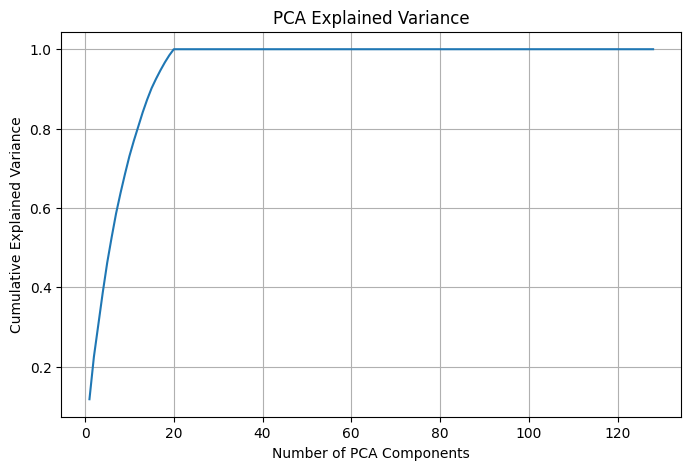

In [18]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, n_components + 1),
    cumulative_variance
)

plt.xlabel("Number of PCA Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Explained Variance")

plt.grid(True)
plt.show()

## 4. Baseline Model — Linear Regression

Linear Regression is used as a baseline model to provide a simple
reference for evaluating the neural network.

The model takes the 56-dimensional pose input and predicts the
128 PCA coefficients representing the clothing deformation.

The test Mean Squared Error (MSE) is used to measure prediction error.

In [19]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Create the linear regression model
linear_model = LinearRegression()

# Train the model
linear_model.fit(X_train, Y_train_pca)

print("Linear Regression training completed!")

Linear Regression training completed!


In [20]:
# Predict PCA coefficients for the test data
Y_test_pred_linear = linear_model.predict(X_test)

# Calculate MSE in PCA space
linear_mse_pca = mean_squared_error(
    Y_test_pca,
    Y_test_pred_linear
)

print("Linear Regression MSE (PCA space):", linear_mse_pca)

Linear Regression MSE (PCA space): 0.009509421068404189


In [21]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

print("PyTorch version:", torch.__version__)

PyTorch version: 2.11.0+cpu


## 5. Neural Network Model

A fully connected neural network is used to learn the relationship
between human pose parameters and clothing deformation.

### Network Architecture

- Input layer: 56 pose features
- Hidden layer 1: 128 neurons
- Activation: ReLU
- Hidden layer 2: 256 neurons
- Activation: ReLU
- Output layer: 128 PCA coefficients

The output represents the reduced clothing deformation obtained after
PCA dimensionality reduction.

In [22]:
class ClothingDeformationNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(56, 128),
            nn.ReLU(),

            nn.Linear(128, 256),
            nn.ReLU(),

            nn.Linear(256, 128)
        )

    def forward(self, x):
        return self.network(x)


# Create the model
model = ClothingDeformationNN()

print(model)

ClothingDeformationNN(
  (network): Sequential(
    (0): Linear(in_features=56, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=128, bias=True)
  )
)


In [23]:
# Convert NumPy arrays to PyTorch tensors

X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
Y_train_tensor = torch.tensor(Y_train_pca, dtype=torch.float32)

X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
Y_val_tensor = torch.tensor(Y_val_pca, dtype=torch.float32)

X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
Y_test_tensor = torch.tensor(Y_test_pca, dtype=torch.float32)

print("Training input:", X_train_tensor.shape)
print("Training target:", Y_train_tensor.shape)
print("Validation input:", X_val_tensor.shape)
print("Validation target:", Y_val_tensor.shape)

Training input: torch.Size([1200, 56])
Training target: torch.Size([1200, 128])
Validation input: torch.Size([400, 56])
Validation target: torch.Size([400, 128])


In [24]:
# Create a dataset from the training tensors
train_dataset = TensorDataset(
    X_train_tensor,
    Y_train_tensor
)

# Create batches of 32 samples
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

print("Number of training batches:", len(train_loader))

Number of training batches: 38


## 6. Model Training

The neural network is trained using Mean Squared Error (MSE) as the loss
function and the Adam optimizer.

### Training Configuration

- Loss function: Mean Squared Error (MSE)
- Optimizer: Adam
- Learning rate: 0.003
- Batch size: 32
- Number of epochs: 100

Training and validation loss are recorded for each epoch to monitor
model performance.

In [25]:
# Loss function
criterion = nn.MSELoss()

# Optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.003
)

print("Loss function: MSE")
print("Optimizer: Adam")
print("Learning rate: 0.003")

Loss function: MSE
Optimizer: Adam
Learning rate: 0.003


In [26]:
# Number of training epochs
num_epochs = 100

# Store losses for plotting later
train_losses = []
val_losses = []

for epoch in range(num_epochs):

    # -------------------------
    # Training
    # -------------------------
    model.train()

    total_train_loss = 0

    for X_batch, Y_batch in train_loader:

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        predictions = model(X_batch)

        # Calculate loss
        loss = criterion(predictions, Y_batch)

        # Backpropagation
        loss.backward()

        # Update model weights
        optimizer.step()

        total_train_loss += loss.item()

    # Average training loss
    average_train_loss = total_train_loss / len(train_loader)

    # -------------------------
    # Validation
    # -------------------------
    model.eval()

    with torch.no_grad():

        val_predictions = model(X_val_tensor)

        val_loss = criterion(
            val_predictions,
            Y_val_tensor
        ).item()

    # Store losses
    train_losses.append(average_train_loss)
    val_losses.append(val_loss)

    # Print progress every 10 epochs
    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch + 1}/{num_epochs} | "
            f"Train Loss: {average_train_loss:.6f} | "
            f"Validation Loss: {val_loss:.6f}"
        )

print("Training completed!")

Epoch 10/100 | Train Loss: 0.005805 | Validation Loss: 0.011611
Epoch 20/100 | Train Loss: 0.002845 | Validation Loss: 0.010575
Epoch 30/100 | Train Loss: 0.001605 | Validation Loss: 0.009861
Epoch 40/100 | Train Loss: 0.001024 | Validation Loss: 0.009305
Epoch 50/100 | Train Loss: 0.000827 | Validation Loss: 0.009209
Epoch 60/100 | Train Loss: 0.000695 | Validation Loss: 0.008956
Epoch 70/100 | Train Loss: 0.000571 | Validation Loss: 0.008790
Epoch 80/100 | Train Loss: 0.000601 | Validation Loss: 0.008636
Epoch 90/100 | Train Loss: 0.000661 | Validation Loss: 0.008415
Epoch 100/100 | Train Loss: 0.000624 | Validation Loss: 0.008140
Training completed!


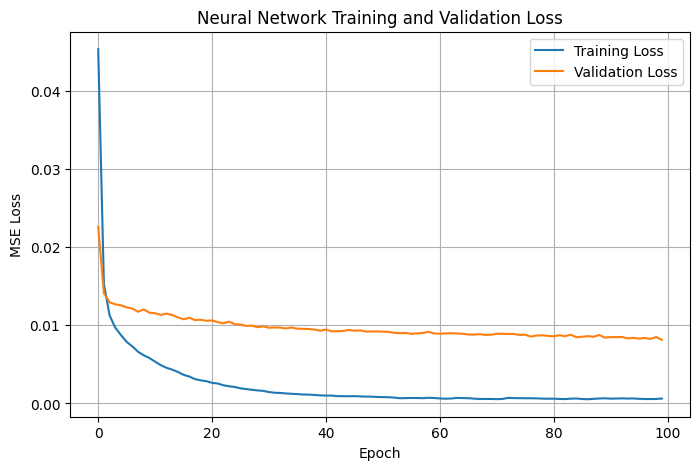

In [27]:
plt.figure(figsize=(8, 5))

plt.plot(
    train_losses,
    label="Training Loss"
)

plt.plot(
    val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Neural Network Training and Validation Loss")

plt.legend()
plt.grid(True)
plt.show()

## 7. Model Evaluation

The trained neural network is evaluated using the unseen test dataset.

The main evaluation metric is Mean Squared Error (MSE). A lower MSE
indicates that the predicted clothing deformation is closer to the
actual deformation.

The neural network is also compared with the Linear Regression baseline
using their test-set MSE values.

In [28]:
# Put the model in evaluation mode
model.eval()

# Make predictions on the test set
with torch.no_grad():
    Y_test_pred_nn = model(X_test_tensor)

# Calculate neural network MSE
nn_mse_pca = mean_squared_error(
    Y_test_pca,
    Y_test_pred_nn.numpy()
)

print("Neural Network MSE (PCA space):", nn_mse_pca)

Neural Network MSE (PCA space): 0.008245365743776618


## 8. Results

The performance of the Linear Regression baseline and the Neural Network
is compared using test-set Mean Squared Error (MSE).

The results are reported in both PCA space and the original clothing
deformation space.

In [29]:
# Calculate percentage reduction in MSE
improvement = (
    (linear_mse_pca - nn_mse_pca)
    / linear_mse_pca
) * 100

print("MSE reduction:", improvement, "%")

MSE reduction: 13.292663302369649 %


In [30]:
# Convert neural network predictions back to original clothing space

Y_test_pred_nn_original = pca.inverse_transform(
    Y_test_pred_nn.numpy()
)

# Also reconstruct the actual test data
Y_test_actual_original = pca.inverse_transform(
    Y_test_pca
)

print(
    "Predicted clothing deformation shape:",
    Y_test_pred_nn_original.shape
)

print(
    "Actual clothing deformation shape:",
    Y_test_actual_original.shape
)

Predicted clothing deformation shape: (400, 6510)
Actual clothing deformation shape: (400, 6510)


In [31]:
# Calculate MSE in the original 6,510-dimensional clothing space

nn_mse_original = mean_squared_error(
    Y_test_actual_original,
    Y_test_pred_nn_original
)

print(
    "Neural Network MSE (original clothing space):",
    nn_mse_original
)

Neural Network MSE (original clothing space): 0.00016212086255044657


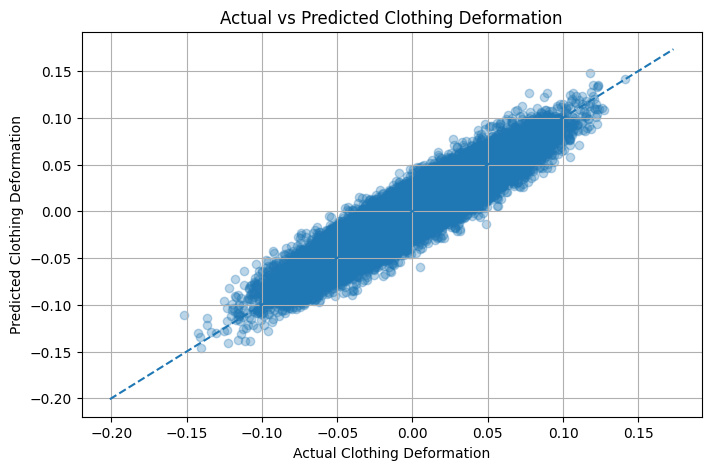

In [32]:
# Compare actual and predicted clothing deformation

plt.figure(figsize=(8, 5))

plt.scatter(
    Y_test_actual_original.flatten()[::50],
    Y_test_pred_nn_original.flatten()[::50],
    alpha=0.3
)

# Perfect prediction line
min_value = Y_test_actual_original.min()
max_value = Y_test_actual_original.max()

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Clothing Deformation")
plt.ylabel("Predicted Clothing Deformation")
plt.title("Actual vs Predicted Clothing Deformation")

plt.grid(True)
plt.show()

In [33]:
# Save the trained neural network

torch.save(
    model.state_dict(),
    "/content/Data_Driven_Clothing_ML/models/clothing_deformation_model.pth"
)

print("Neural network model saved successfully!")

Neural network model saved successfully!


In [34]:
import pandas as pd

results = pd.DataFrame({
    "Metric": [
        "PCA dimensions",
        "Variance retained (%)",
        "Linear Regression Test MSE",
        "Neural Network Test MSE (PCA space)",
        "MSE reduction (%)",
        "Neural Network Test MSE (original space)"
    ],
    "Value": [
        128,
        cumulative_variance[-1] * 100,
        linear_mse_pca,
        nn_mse_pca,
        improvement,
        nn_mse_original
    ]
})

results.to_csv(
    "/content/Data_Driven_Clothing_ML/results/model_results.csv",
    index=False
)

print("Results saved successfully!")
print()
print(results)

Results saved successfully!

                                     Metric       Value
0                            PCA dimensions  128.000000
1                     Variance retained (%)   99.982984
2                Linear Regression Test MSE    0.009509
3       Neural Network Test MSE (PCA space)    0.008245
4                         MSE reduction (%)   13.292663
5  Neural Network Test MSE (original space)    0.000162


### Key Results

- PCA components: 128
- Variance retained: 99.9829%
- Linear Regression test MSE: 0.0095094
- Neural Network test MSE: 0.0082453
- MSE reduction compared with Linear Regression: 13.29%
- Neural Network MSE in original deformation space: 0.0001621

## 9. Limitations

- The original numerical dataset used in the reference paper was not
  available for this implementation.
- A synthetic, simulation-inspired dataset was therefore generated.
- The generated deformation values represent a high-dimensional
  numerical representation and are not a physically simulated garment.
- The current implementation uses 2,000 samples, which is smaller than
  the dataset described in the reference paper.
- The results obtained in this notebook should therefore not be directly
  compared with the numerical results reported in the paper.

## 10. Conclusion

This project demonstrates a simplified data-driven approach for
predicting clothing deformation from human pose parameters.

PCA was used to reduce the high-dimensional clothing deformation output,
while Linear Regression provided a baseline for comparison.

The fully connected neural network achieved a lower test MSE than the
Linear Regression baseline on the synthetic dataset.

Overall, the project demonstrates how dimensionality reduction and
neural networks can be combined to learn a mapping from pose parameters
to clothing deformation.

## 11. Live Prediction Demo

The trained neural network can be used to predict clothing deformation
for a previously unseen pose.

The predicted 128 PCA coefficients are converted back into the original
6,510-dimensional deformation representation using the fitted PCA model.

In [35]:
# Select one unseen test sample
sample_index = 0

sample_input = X_test_tensor[sample_index].unsqueeze(0)

# Generate prediction
model.eval()

with torch.no_grad():
    sample_prediction_pca = model(sample_input).numpy()

# Convert prediction back to the original 6510-dimensional space
sample_prediction = pca.inverse_transform(sample_prediction_pca)

# Actual deformation
sample_actual = Y_test[sample_index].reshape(1, -1)

# Calculate MSE for this sample
sample_mse = mean_squared_error(sample_actual, sample_prediction)

print("Input pose dimensions:", sample_input.shape)
print("Predicted PCA dimensions:", sample_prediction_pca.shape)
print("Predicted deformation dimensions:", sample_prediction.shape)
print("Sample test MSE:", sample_mse)

Input pose dimensions: torch.Size([1, 56])
Predicted PCA dimensions: (1, 128)
Predicted deformation dimensions: (1, 6510)
Sample test MSE: 0.00021001616639298974


### Demo Interpretation

For the selected unseen test sample, the model receives 56 pose features
and predicts 128 PCA coefficients. These coefficients are transformed
back into 6,510 clothing deformation values using inverse PCA.

For this sample, the prediction has a Mean Squared Error (MSE) of
0.0002100 in the original deformation space.